## Лабораторная работа 3. Кластерный анализ методом DBSCAN

**Курс:** Анализ данных на Python

**Студент:** Муравья Никита

**Задача:** «Economics of Cities»

DBSCAN считает кластером область высокой плотности. Точка $p$ ядровая, если в её $\varepsilon$-окрестности $N_\varepsilon(p) = \{q : \rho(p, q) \le \varepsilon\}$ лежит не меньше `min_samples` точек, включая саму $p$. Кластер состоит из точек, связанных по плотности через цепочки ядровых точек. Точки, недостижимые ни из одного ядра, объявляются **шумом**. Число кластеров алгоритм определяет сам.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.metrics import (silhouette_score, silhouette_samples,
                             calinski_harabasz_score, davies_bouldin_score, adjusted_rand_score)
from sklearn.cluster import DBSCAN, KMeans
from sklearn.neighbors import NearestNeighbors
from scipy.cluster.hierarchy import linkage, fcluster

sns.set(style="whitegrid", palette="Set2")
RANDOM_STATE = 42  # фиксируем случайность, чтобы текст ниже совпадал с выводом при перезапуске

---
### Данные

Подготовка та же, что в работе 1: исключаем Каир и Джакарту с пропусками, остальные 46 городов стандартизуем.

In [2]:
df_raw = pd.read_csv("Econom_Cities_data.csv", sep=";", decimal=",", index_col="City")
df_raw = df_raw.replace(-9999, np.nan)
df = df_raw.dropna()
names = df.index.str.replace("_", " ")
scaler = StandardScaler()
X = scaler.fit_transform(df)
xy_pca = PCA(n_components=2, random_state=RANDOM_STATE).fit_transform(X)  # только для рисунков

---
### Функции

In [3]:
def plot_clusters(xy, labels, title, xlabel, ylabel, annotate=True):
    """Рисует точки xy (n x 2) с раскраской по кластерам.

    labels   -- метки кластеров, шум DBSCAN (-1) рисуется серыми крестиками;
    annotate -- подписывать ли города (их 46, подписи читаются).
    """
    fig, ax = plt.subplots(figsize=(9, 6))
    for k in np.unique(labels):
        mask = labels == k
        if k == -1:
            ax.scatter(*xy[mask].T, c="grey", marker="x", s=60, label="шум")
        else:
            ax.scatter(*xy[mask].T, s=60, edgecolor="k", linewidth=0.5, label=f"кластер {k}")
    if annotate:
        for (x, y), name in zip(xy, names):
            ax.annotate(name, (x, y), xytext=(3, 3), textcoords="offset points", fontsize=7)
    ax.set(title=title, xlabel=xlabel, ylabel=ylabel)
    ax.legend()
    plt.show()

In [4]:
def relabel(labels, by="Salary"):
    """Перенумеровывает кластеры 0, 1, ... по возрастанию среднего признака `by`.

    Номера кластеров у разных методов случайны, а так кластер 0 всегда самый
    низкооплачиваемый и разные методы удобно сравнивать. Шум (-1) не трогаем.
    """
    labels = np.asarray(labels)
    order = df[by].groupby(labels).mean().drop(-1, errors="ignore").sort_values().index
    mapping = {old: new for new, old in enumerate(order)} | {-1: -1}
    return np.array([mapping[label] for label in labels])

In [5]:
def silhouette_wo_noise(labels):
    """Силуэт по нешумовым точкам (шум не кластер); NaN, если кластеров меньше двух."""
    mask = labels != -1
    if len(np.unique(labels[mask])) < 2:
        return np.nan
    return silhouette_score(X[mask], labels[mask])

In [6]:
def profile(labels):
    """Размер, средние признаки, Salary/Price и состав каждого кластера (шум идёт строкой -1)."""
    table = df.assign(Salary_to_Price=df.Salary / df.Price).groupby(labels).mean().round(2)
    table.insert(0, "size", pd.Series(labels).value_counts().sort_index().values)
    table["cities"] = df.index.to_series().groupby(labels).agg(", ".join)
    return table

---
### DBSCAN: выбор параметров

**1. `min_samples`.** Обычные эвристики: $\text{min\_samples} \ge d + 1$ и $\text{min\_samples} \approx 2d$, при $d = 3$ это 4–6. На 46 точках большие значения превращают в шум почти всю выборку, поэтому берём нижнюю границу, **`min_samples = 4`**.

In [7]:
MIN_SAMPLES = 4

**2. `eps`.** Строим отсортированные расстояния до $k$-го соседа при $k = \text{min\_samples} - 1 = 3$. Внутри плотных областей они маленькие, у выбросов большие, а `eps` берут в «колене» кривой. Колено ищем как точку, наиболее удалённую от хорды между концами кривой.

колено кривой 3-расстояний: 0.845


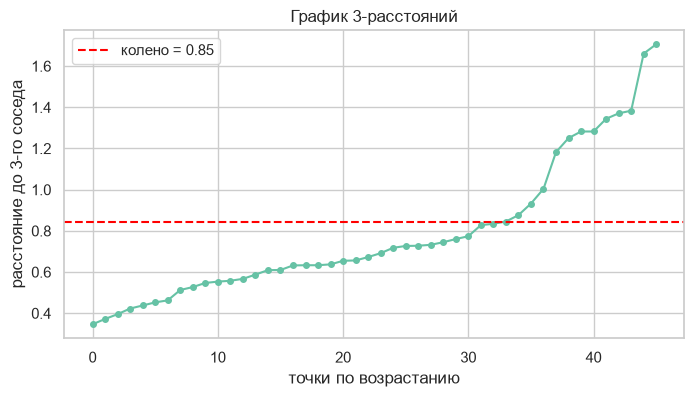

In [8]:
dist, _ = NearestNeighbors(n_neighbors=MIN_SAMPLES).fit(X).kneighbors(X)  # столбец 0 -- сама точка
k_dist = np.sort(dist[:, -1])
idx = np.arange(len(k_dist))
chord = k_dist[0] + (k_dist[-1] - k_dist[0]) * idx / idx[-1]
knee = k_dist[np.argmax(chord - k_dist)]
print(f"колено кривой 3-расстояний: {knee:.3f}")

plt.figure(figsize=(8, 4))
plt.plot(idx, k_dist, "o-", ms=4)
plt.axhline(knee, ls="--", color="red", label=f"колено = {knee:.2f}")
plt.title("График 3-расстояний")
plt.xlabel("точки по возрастанию")
plt.ylabel("расстояние до 3-го соседа")
plt.legend()
plt.show()

Колено около $0{,}85$, правее него кривая резко уходит вверх. Проверим окрестность колена сеткой параметров.

In [9]:
rows = []
for min_samples in [3, 4, 5]:
    for eps in np.round(np.arange(0.4, 1.21, 0.1), 2):
        labels = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(X)
        rows.append({"eps": eps, "min_samples": min_samples,
                     "n_clusters": len(set(labels) - {-1}), "n_noise": (labels == -1).sum(),
                     "silhouette": silhouette_wo_noise(labels)})
grid = pd.DataFrame(rows)
grid.pivot(index="eps", columns="min_samples", values=["n_clusters", "n_noise", "silhouette"]).round(3)

n_clusters           n_noise             silhouette              
min_samples          3    4    5       3     4     5          3      4      5
eps                                                                          
0.4                4.0  2.0  1.0    30.0  37.0  41.0      0.486  0.444    NaN
0.5                3.0  1.0  1.0    23.0  35.0  36.0      0.489    NaN    NaN
0.6                2.0  3.0  2.0    16.0  21.0  28.0      0.554  0.477  0.726
0.7                2.0  3.0  3.0    11.0  11.0  21.0      0.540  0.356  0.576
0.8                2.0  2.0  2.0     8.0   8.0   9.0      0.512  0.512  0.523
0.9                1.0  1.0  2.0     8.0   8.0   8.0        NaN    NaN  0.512
1.0                1.0  1.0  1.0     8.0   8.0   8.0        NaN    NaN    NaN
1.1                1.0  1.0  1.0     7.0   7.0   7.0        NaN    NaN    NaN
1.2                1.0  1.0  1.0     4.0   4.0   5.0        NaN    NaN    NaN

Выбираем **`eps = 0.8`**, ближайший к колену узел сетки:

* при $\varepsilon \ge 0{,}9$ всё сливается в один кластер, при $\varepsilon \le 0{,}6$ в шум уходит от 21 до 37 городов;
* при $\varepsilon = 0{,}8$ получаем 2 кластера и 8 шумовых точек (17 %), силуэт без шума $0{,}51$;
* пары $(0{,}8;\ 3)$ и $(0{,}9;\ 5)$ дают то же разбиение, решение устойчиво.

Вариант $\varepsilon = 0{,}7$ рассмотрим ниже отдельно.

In [10]:
EPS = 0.8
labels_db = relabel(DBSCAN(eps=EPS, min_samples=MIN_SAMPLES).fit_predict(X))
profile(labels_db)

,size,Work,Price,Salary,Salary_to_Price,cities
-1,8,1900.38,99.92,61.26,0.61,"Geneva, Helsinki, Hong_Kong, Oslo, Stockholm, ..."
0,19,1959.21,50.12,14.79,0.29,"Athens, Bogota, Bombay, Buenos_Aires, Caracas,..."
1,19,1792.00,77.53,55.16,0.72,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."


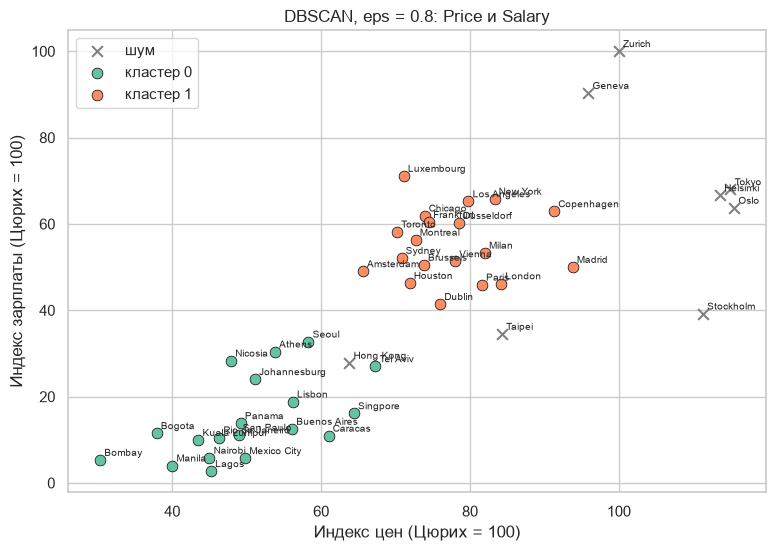

In [11]:
plot_clusters(df[["Price", "Salary"]].values, labels_db, "DBSCAN, eps = 0.8: Price и Salary",
              "Индекс цен (Цюрих = 100)", "Индекс зарплаты (Цюрих = 100)")

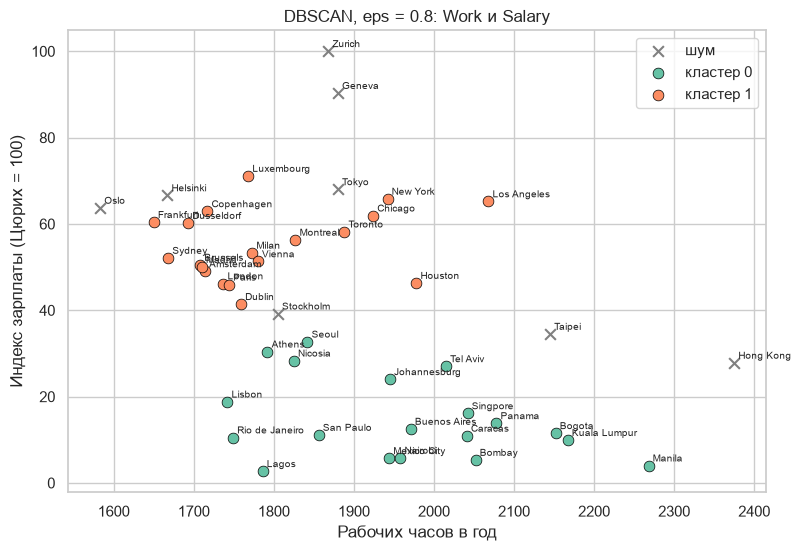

In [12]:
plot_clusters(df[["Work", "Salary"]].values, labels_db, "DBSCAN, eps = 0.8: Work и Salary",
              "Рабочих часов в год", "Индекс зарплаты (Цюрих = 100)")

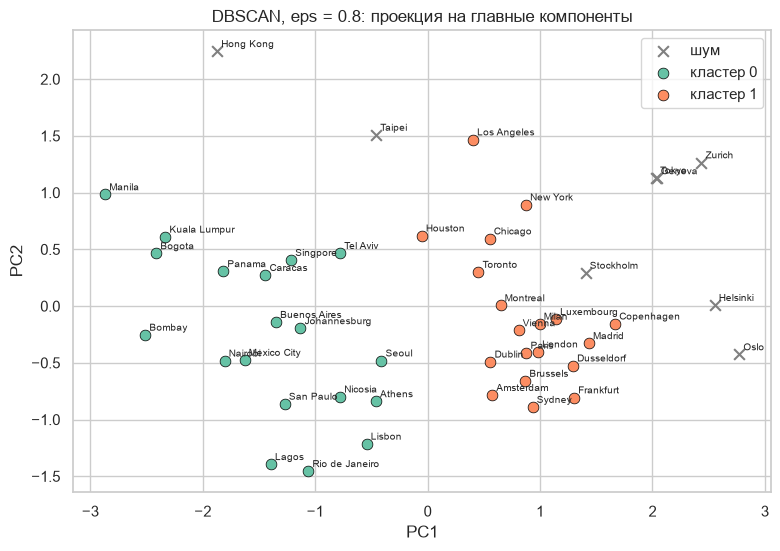

In [13]:
plot_clusters(xy_pca, labels_db, "DBSCAN, eps = 0.8: проекция на главные компоненты", "PC1", "PC2")

---
### Шум

У шумовых городов меньше `min_samples` соседей в радиусе $\varepsilon$, и до них не добраться по цепочке ядер. Посмотрим z-оценки, самый выделяющийся признак и расстояние до третьего соседа.

In [14]:
z = pd.DataFrame(X, index=df.index, columns=df.columns)
noise = labels_db == -1
df[noise].join(z[noise].add_prefix("z_").round(2)).assign(
    most_extreme=z[noise].abs().idxmax(axis=1),
    dist_to_3rd=dist[noise, -1].round(2),
).sort_values("dist_to_3rd", ascending=False)

,Work,Price,Salary,z_Work,z_Price,z_Salary,most_extreme,dist_to_3rd
City,,,,,,,,
Hong_Kong,2375.0,63.8,27.8,2.87,-0.30,-0.48,Work,1.71
Zurich,1868.0,100.0,100.0,-0.07,1.41,2.47,Salary,1.66
Oslo,1583.0,115.5,63.7,-1.72,2.15,0.99,Price,1.38
Stockholm,1805.0,111.3,39.2,-0.43,1.95,-0.01,Price,1.37
Taipei,2145.0,84.3,34.5,1.54,0.67,-0.21,Work,1.34
Geneva,1880.0,95.9,90.3,0.00,1.22,2.07,Salary,1.28
Tokyo,1880.0,115.0,68.0,0.00,2.12,1.16,Price,1.28
Helsinki,1667.0,113.6,66.6,-1.23,2.06,1.10,Price,1.18


Шумовые города делятся на два типа.

**«Дорогие одиночки»: Женева, Цюрих, Хельсинки, Осло, Стокгольм, Токио.** У Цюриха и Женевы экстремальные зарплаты ($z_\text{Salary} = +2{,}5$ и $+2{,}1$), у Осло, Хельсинки, Токио и Стокгольма цены ($z_\text{Price}$ до $+2{,}15$). Друг на друга они не похожи и плотного сгустка не образуют. Слишком особенные, чтобы считаться толпой :)

**«Трудоголики-одиночки»: Гонконг и Тайбэй.** Аномально длинный рабочий год (у Гонконга 2375 часов, рекорд выборки) при средних ценах. На бедные города с длинным рабочим годом они не похожи, на Запад тоже.

Куда эти города отнёс k-means из работы 2:

In [15]:
labels_km = relabel(KMeans(n_clusters=4, n_init=20, random_state=RANDOM_STATE).fit_predict(X))
pd.crosstab(pd.Series(labels_db, name="DBSCAN"), pd.Series(labels_km, name="k-means, k = 4"))

"k-means, k = 4",0,1,2,3
DBSCAN,,,,
-1,2,0,0,6
0,8,11,0,0
1,0,0,19,0


Весь кластер «дорого и богато» DBSCAN объявил шумом: k-means обязан собрать эти шесть городов хоть в какую-то группу, а DBSCAN видит, что плотности там нет. Гонконг и Тайбэй у k-means числятся трудоголиками, но лежат на дальней периферии этой группы.

**Для сравнения: `eps = 0.7`.**

In [16]:
profile(relabel(DBSCAN(eps=0.7, min_samples=MIN_SAMPLES).fit_predict(X)))

,size,Work,Price,Salary,Salary_to_Price,cities
-1,11,1936.45,89.22,55.17,0.59,"Bombay, Geneva, Helsinki, Hong_Kong, Houston, ..."
0,14,1998.00,50.41,11.82,0.23,"Bogota, Buenos_Aires, Caracas, Johannesburg, K..."
1,4,1800.25,54.05,27.55,0.51,"Athens, Lisbon, Nicosia, Seoul"
2,17,1764.82,77.72,55.09,0.72,"Amsterdam, Brussels, Chicago, Copenhagen, Dubl..."


К шуму добавляются Бомбей, Хьюстон и Лос-Анджелес, и появляется мини-кластер из Афин, Лиссабона, Никосии и Сеула. Он держится на четырёх точках и пропадает при малейшем увеличении `eps`, поэтому оставляем $\varepsilon = 0{,}8$.

---
### Интерпретация

| Метка | Название | Размер | Work, ч | Price | Salary | Salary/Price |
|---|---|---|---|---|---|---|
| 0 | «Небогатые города» | 19 | 1959 | 50 | 15 | 0,29 |
| 1 | «Благополучный Запад» | 19 | 1792 | 78 | 55 | **0,72** |
| −1 | шум | 8 | 1900 | 100 | 61 | 0,61 |

**Кластер 0** объединил трудоголиков и периферию из работы 2 в одну плотную область: разрежения между ними нет, граница по `Work` плавная. Именно на ней расходились Ward и k-means.

**Кластер 1** состоит из тех же 19 городов, что «благополучный Запад» у Уорда и k-means.

---
### Выводы

In [17]:
labels_ward = relabel(fcluster(linkage(X, "ward"), 4, criterion="maxclust"))
pd.DataFrame({
    "кластеров": [4, 4, len(set(labels_db) - {-1})],
    "шум": [0, 0, (labels_db == -1).sum()],
    "silhouette": [silhouette_wo_noise(labels_ward), silhouette_wo_noise(labels_km), silhouette_wo_noise(labels_db)],
    "ARI с k-means": [adjusted_rand_score(labels_ward, labels_km), 1.0, adjusted_rand_score(labels_db, labels_km)],
}, index=["Ward (работа 1)", "k-means (работа 2)", f"DBSCAN eps={EPS} (работа 3)"]).round(3)

,кластеров,шум,silhouette,ARI с k-means
Ward (работа 1),4,0,0.355,0.838
k-means (работа 2),4,0,0.366,1.000
DBSCAN eps=0.8 (работа 3),2,8,0.512,0.743


1. При `min_samples = 4` и `eps = 0.8` DBSCAN нашёл 2 кластера и 8 шумовых городов.
2. Силуэт у DBSCAN выше, чем у Уорда и k-means, но только потому, что трудные точки ушли в шум, а силуэт считается без него.
3. «Благополучный Запад» совпадает у всех трёх методов, это самая надёжная группа. Группу «дорого и богато» DBSCAN считает шумом, границу между трудоголиками и периферией не видит.
4. На 46 точках плотность оценивается грубо, и шаг `eps` в $0{,}1$ меняет число кластеров. Для этих данных DBSCAN полезнее как детектор нетипичных городов, чем как способ построить типологию.